# 43 - Phase 0: Reactor-Analyzer Feasibility Check (does observing `z_A` resolve the confounds?)

Phase 0 of `docs/Manuscript/system_ii_analyzer_rework_plan.md`. Tests, deterministically and
without touching any library code or training anything, whether adding reactor composition
(`z_A`, already computed as `y[0]` in `src/cstr_sbi/recycle/physics.py` but never exposed as
an observed channel) collapses the two confirmed identifiability limits from `nb39-42`:
`(alpha, z_A0_eff)` (curved/sign-changing, confirmed at multiple points) and
`(eta_col, z_A0_eff)` (simpler, positive, confirmed away from the `eta_col=1.0` boundary).

**Method:** build an ad-hoc "S-C-like" feature function (`SB_CHANNELS + ["z_A"]`, same
per-channel stats via `summaries.channel_summaries` + the existing 12 physics features via
`summaries.physics_features`) entirely in this notebook -- no changes to
`src/cstr_sbi/recycle/summaries.py` yet (that's Phase 1, only worth doing if this check
passes). Recompute the noise-calibrated FIM (`cov_offdiag_corr`, the corrected metric) and a
grid-scan at the same operating points already characterized in `nb39-42`, with and without
`z_A` in the feature set, side by side.

**Decision gate:** if the coupling collapses at these points the way `(alpha, beta_r)` did
under raw trajectory (`nb29b`), proceed to Phase 1 of the rework plan. If not, stop and
reconsider before any retraining.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax.numpy as jnp

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from cstr_sbi.recycle.physics import (
    PARAM_NAMES, NOMINAL_CTRL_SB, NOMINAL_INLET,
    simulate_trajectory_explicit_jit, extract_observations_explicit,
)
from cstr_sbi.recycle.priors import PRIOR_LOW_5D, PRIOR_HIGH_5D
from cstr_sbi.recycle.simulator import nominal_warm_start
from cstr_sbi.recycle.summaries import (
    compute_summaries, RAW_INDEX, SB_CHANNELS, channel_summaries, physics_features,
)
from fim_utils import compute_fim, offdiag_ratio, cov_offdiag_corr, crb_report
import identifiability_scan as idscan

RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

STRUCTURE = 'S-B'
NOISE_PCT = 0.003
EPS_FIM = np.array([0.02, 0.02, 0.02, 0.02, 0.01])
Y0_FIM = np.asarray(nominal_warm_start('S-B'))
ALPHA_IDX, BETA_R_IDX, ETA_COL_IDX, XI_REB_IDX, Z_A0_IDX = range(5)

SC_CHANNELS = list(SB_CHANNELS) + ['z_A']  # the proposed reactor-analyzer channel set
print('S-B channels:', SB_CHANNELS)
print('S-C channels (proposed):', SC_CHANNELS)

S-B channels: ['T_r', 'T_j', 'Q_j', 'T_reb', 'Q_reb', 'F_R_norm', 'F_B_norm', 'R_norm', 'V_norm']
S-C channels (proposed): ['T_r', 'T_j', 'Q_j', 'T_reb', 'Q_reb', 'F_R_norm', 'F_B_norm', 'R_norm', 'V_norm', 'z_A']


In [2]:
def sim_raw_full(theta_np, seed=None, noise_pct=NOISE_PCT):
    th = jnp.array(theta_np, dtype=jnp.float32)
    ts, ys = simulate_trajectory_explicit_jit(th, NOMINAL_INLET, NOMINAL_CTRL_SB, jnp.array(Y0_FIM),
                                               t_final=2.0, n_save=120, rtol=1e-3, atol=1e-5)
    raw = np.asarray(extract_observations_explicit(ys, th, NOMINAL_CTRL_SB))
    t_h = np.asarray(ts)
    if seed is not None:
        rng = np.random.default_rng(seed)
        scale = np.maximum(np.max(np.abs(raw), axis=0), 1e-6)
        raw = raw + rng.normal(0, noise_pct * scale, raw.shape)
    return raw, t_h


def channel_stats_only(raw, t, channels):
    """summaries.channel_summaries restricted to an arbitrary channel list (no physics
    features) -- the building block for both the S-B and ad-hoc S-C feature functions."""
    idx = [RAW_INDEX[c] for c in channels]
    return channel_summaries(raw[:, idx], t)


def feat_sb_fim(theta, seed):
    """Exact reproduction of compute_summaries('S-B') -- the baseline, unchanged."""
    raw, t_h = sim_raw_full(theta, seed)
    return compute_summaries(raw, 'S-B', t_h)


def feat_sc_fim(theta, seed):
    """Ad-hoc S-C-like feature: S-B's 9 channels + z_A (10 channels x 6 stats = 60-D),
    plus the same 12 physics features compute_summaries already includes -- 72-D total.
    Built entirely from public summaries.py functions, no library changes."""
    raw, t_h = sim_raw_full(theta, seed)
    return np.concatenate([channel_stats_only(raw, t_h, SC_CHANNELS), physics_features(raw, t_h)])


# Sanity check: feat_sc_fim's first 66 entries (9-channel stats + 12 physics) should exactly
# match feat_sb_fim's, since we only appended z_A's 6 stats -- order needs fixing for that,
# so instead just check dimensionality and that a no-noise call runs cleanly.
theta_chk = np.array([1.0, 1.0, 1.0, 1.0, 0.90], dtype=np.float32)
s_sb = feat_sb_fim(theta_chk, seed=0)
s_sc = feat_sc_fim(theta_chk, seed=0)
print(f'S-B feature dim: {s_sb.shape[0]}   S-C feature dim: {s_sc.shape[0]} (+{s_sc.shape[0]-s_sb.shape[0]} from z_A)')

S-B feature dim: 66   S-C feature dim: 72 (+6 from z_A)


## FIM check at every point already characterized in `nb39`/`nb40`/`nb41`/`nb42`

Same `EPS_FIM`, same fixed nominal warm start, same noise-seed-robustness convention
(3 seed offsets) as every prior notebook in this arc -- only the feature function changes.

In [3]:
CHECK_POINTS = [
    dict(name='Nominal', theta=np.array([1.00, 1.00, 1.00, 1.00, 0.90]), pairs=[('eta_col', 'z_A0_eff'), ('alpha', 'eta_col')]),
    dict(name='nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80)', theta=np.array([1.00, 1.00, 1.00, 0.70, 0.80]), pairs=[('alpha', 'z_A0_eff')]),
    dict(name='W2 (alpha=0.85)', theta=np.array([0.85, 1.00, 1.00, 1.00, 0.90]), pairs=[('alpha', 'z_A0_eff')]),
    dict(name='nb40 P4 (random prior draw)', theta=np.array([0.826, 1.177, 0.969, 0.802, 0.921]), pairs=[('alpha', 'z_A0_eff'), ('eta_col', 'z_A0_eff')]),
    dict(name='nb41 interior eta_col=0.85, z_A0_eff=0.80', theta=np.array([1.00, 1.00, 0.85, 1.00, 0.80]), pairs=[('eta_col', 'z_A0_eff')]),
]
PARAM_IDX = {n: i for i, n in enumerate(PARAM_NAMES)}

fim_rows = []
for point in CHECK_POINTS:
    theta_pt = point['theta'].astype(np.float64)
    print(f"\n=== {point['name']} (theta={np.round(theta_pt, 3).tolist()}) ===")
    for p1, p2 in point['pairs']:
        ia, ib = PARAM_IDX[p1], PARAM_IDX[p2]
        print(f'  pair ({p1}, {p2}):')
        for label, fn in [('S-B (no analyzer)', feat_sb_fim), ('S-C (+z_A analyzer)', feat_sc_fim)]:
            corrs = []
            for off in [0, 500, 999]:
                FIM_rep = compute_fim(fn, theta_pt, EPS_FIM, seed_offset=off)
                corr = cov_offdiag_corr(FIM_rep, ia, ib)
                corrs.append(corr)
            print(f'    {label:22s}: corr(cov) = {np.mean(corrs):+.3f}  (seeds: {[round(c,3) for c in corrs]})')
            fim_rows.append({'point': point['name'], 'pair': f'{p1}/{p2}', 'representation': label, 'corr_mean': np.mean(corrs)})

fim_df = pd.DataFrame(fim_rows)
fim_df.to_csv(RESULTS / '43_analyzer_feasibility_fim.csv', index=False)


=== Nominal (theta=[1.0, 1.0, 1.0, 1.0, 0.9]) ===
  pair (eta_col, z_A0_eff):


    S-B (no analyzer)     : corr(cov) = +0.791  (seeds: [0.761, 0.79, 0.821])


    S-C (+z_A analyzer)   : corr(cov) = +0.631  (seeds: [0.607, 0.614, 0.674])
  pair (alpha, eta_col):


    S-B (no analyzer)     : corr(cov) = -0.706  (seeds: [-0.659, -0.712, -0.747])


    S-C (+z_A analyzer)   : corr(cov) = -0.535  (seeds: [-0.495, -0.536, -0.574])

=== nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) (theta=[1.0, 1.0, 1.0, 0.7, 0.8]) ===
  pair (alpha, z_A0_eff):


    S-B (no analyzer)     : corr(cov) = -0.656  (seeds: [-0.596, -0.646, -0.726])


... (5 outputs left out)

    S-B (no analyzer)     : corr(cov) = +0.317  (seeds: [0.281, 0.303, 0.367])


    S-C (+z_A analyzer)   : corr(cov) = +0.303  (seeds: [0.271, 0.282, 0.357])

=== nb41 interior eta_col=0.85, z_A0_eff=0.80 (theta=[1.0, 1.0, 0.85, 1.0, 0.8]) ===
  pair (eta_col, z_A0_eff):


    S-B (no analyzer)     : corr(cov) = +0.732  (seeds: [0.689, 0.743, 0.763])


    S-C (+z_A analyzer)   : corr(cov) = +0.555  (seeds: [0.539, 0.527, 0.599])


representation                                                  S-B (no analyzer)  \
point                                         pair                                  
Nominal                                       alpha/eta_col                -0.706   
                                              eta_col/z_A0_eff              0.791   
W2 (alpha=0.85)                               alpha/z_A0_eff                0.743   
nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) alpha/z_A0_eff               -0.656   
nb40 P4 (random prior draw)                   alpha/z_A0_eff                0.587   
                                              eta_col/z_A0_eff              0.317   
nb41 interior eta_col=0.85, z_A0_eff=0.80     eta_col/z_A0_eff              0.732   

representation                                                  S-C (+z_A analyzer)  \
point                                         pair                                    
Nominal                                       alpha/eta_col                  -0.535   
                                              eta_col/z_A0_eff                0.631   
W2 (alpha=0.85)                               alpha/z_A0_eff                  0.751   
nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) alpha/z_A0_eff                 -0.342   
nb40 P4 (random prior draw)                   alpha/z_A0_eff                  0.601   
                                              eta_col/z_A0_eff                0.303   
nb41 interior eta_col=0.85, z_A0_eff=0.80     eta_col/z_A0_eff                0.555   

representation                                                  abs_reduction  
point                                         pair                             
Nominal                                       alpha/eta_col             0.171  
                                              eta_col/z_A0_eff          0.159  
W2 (alpha=0.85)                               alpha/z_A0_eff           -0.008  
nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) alpha/z_A0_eff            0.314  
nb40 P4 (random prior draw)                   alpha/z_A0_eff           -0.014  
                                              eta_col/z_A0_eff          0.014  
nb41 interior eta_col=0.85, z_A0_eff=0.80     eta_col/z_A0_eff          0.177

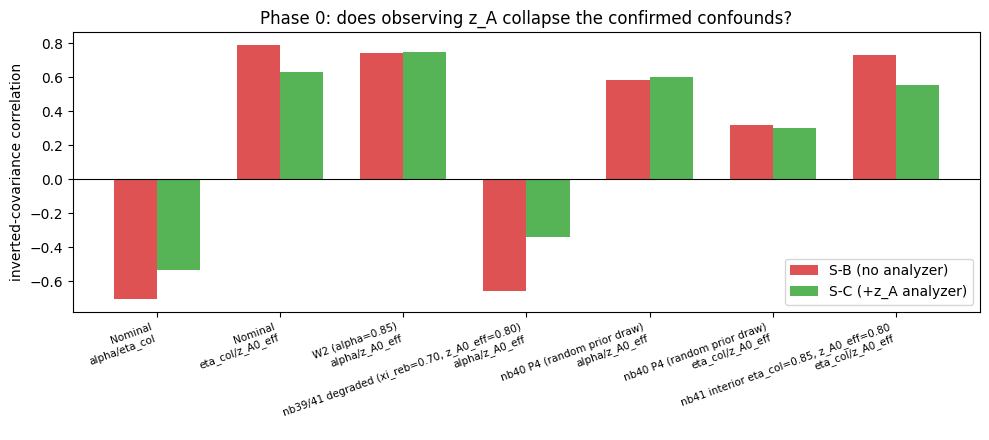

In [4]:
pivot = fim_df.pivot_table(index=['point', 'pair'], columns='representation', values='corr_mean')
pivot['abs_reduction'] = pivot['S-B (no analyzer)'].abs() - pivot['S-C (+z_A analyzer)'].abs()
display(pivot.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [f'{p}\n{pr}' for p, pr in pivot.index]
x = np.arange(len(pivot))
width = 0.35
ax.bar(x - width/2, pivot['S-B (no analyzer)'], width, label='S-B (no analyzer)', color='tab:red', alpha=0.8)
ax.bar(x + width/2, pivot['S-C (+z_A analyzer)'], width, label='S-C (+z_A analyzer)', color='tab:green', alpha=0.8)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7.5, rotation=20, ha='right')
ax.set_ylabel('inverted-covariance correlation')
ax.set_title('Phase 0: does observing z_A collapse the confirmed confounds?')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / '43_analyzer_feasibility_fim.png', dpi=170, bbox_inches='tight')
plt.show()

## Grid-scan visual confirmation, at the strongest-established point for each pair

`(eta_col, z_A0_eff)` at nominal (strongest established coupling, `+0.76`) and
`(alpha, z_A0_eff)` at the degraded point (`nb39`'s original point, `-0.60`). Uses
`identifiability_scan.run_scan_custom` (already built for exactly this purpose in `nb29b`
Section 3) with the ad-hoc S-C feature function and a freshly-computed normalising std.

In [5]:
def feat_grid_sb(theta):
    raw, t_h = sim_raw_full(theta, seed=None)
    return compute_summaries(raw, 'S-B', t_h)


def feat_grid_sc(theta):
    raw, t_h = sim_raw_full(theta, seed=None)
    return np.concatenate([channel_stats_only(raw, t_h, SC_CHANNELS), physics_features(raw, t_h)])


print('Computing normalising std for both representations (300 fresh prior draws each)...')
norm_std_sb = idscan.compute_norm_std(feat_grid_sb, n_samples=300, seed=10)
norm_std_sc = idscan.compute_norm_std(feat_grid_sc, n_samples=300, seed=10)

GRID_SCAN_CASES = [
    dict(p1='eta_col', p2='z_A0_eff', truth=np.array([1.00, 1.00, 1.00, 1.00, 0.90], dtype=np.float32),
         grid1=(0.50, 1.00, 27), grid2=(0.70, 0.95, 27), label='Nominal'),
    dict(p1='alpha', p2='z_A0_eff', truth=np.array([1.00, 1.00, 1.00, 0.70, 0.80], dtype=np.float32),
         grid1=(0.40, 1.20, 27), grid2=(0.70, 0.95, 27), label='nb39/41 degraded point'),
]

grid_results = {}
for case in GRID_SCAN_CASES:
    g1_sb, g2_sb, d_sb = idscan.run_scan_custom(case['p1'], case['p2'], case['truth'], case['grid1'], case['grid2'],
                                                  feat_grid_sb, norm_std_sb, label='S-B (no analyzer)')
    g1_sc, g2_sc, d_sc = idscan.run_scan_custom(case['p1'], case['p2'], case['truth'], case['grid1'], case['grid2'],
                                                  feat_grid_sc, norm_std_sc, label='S-C (+z_A analyzer)')
    grid_results[(case['p1'], case['p2'])] = dict(case=case, sb=(g1_sb, g2_sb, d_sb), sc=(g1_sc, g2_sc, d_sc))

Computing normalising std for both representations (300 fresh prior draws each)...


  norm_std computed from 300/300 valid prior draws


  norm_std computed from 300/300 valid prior draws



eta_col\z_A0_eff distance grid (S-B (no analyzer), 66-D features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.500      2.3  2.3  2.3  2.3  2.3  2.3  2.3  2.2  2.3  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1
0.519      2.3  2.3  2.3  2.3  2.3  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.1  2.3  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1
0.538      2.3  2.3  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.1  2.2  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.0  2.0  2.0
0.558      2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.1  2.0  2.0  2.0  2.0  2.0
0.577      2.2  2.2  2.2  2.2  2.2  2.2  2.2  2.1  2.2  2.1  2.1  2.1  2.1  2.2  2.1  2.1  2.1  2.1  2.0  2.0  2.0  2.0  2.0  2.0  2.0  2.0  2.0
0.596      2.2  2.2  2.2  2.2  2.2  2.1  2.1  2.1  2.1  2.1  2


eta_col\z_A0_eff distance grid (S-C (+z_A analyzer), 72-D features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.500      1.6  1.6  1.6  1.6  1.6  1.5  1.5  1.5  1.5  1.5  1.5  1.5  1.5  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.3  1.3  1.3  1.3  1.3
0.519      1.6  1.6  1.6  1.5  1.5  1.5  1.5  1.5  1.5  1.5  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3
0.538      1.6  1.6  1.5  1.5  1.5  1.5  1.5  1.5  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3
0.558      1.5  1.5  1.5  1.5  1.5  1.5  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.2  1.2
0.577      1.5  1.5  1.5  1.5  1.5  1.4  1.4  1.4  1.4  1.4  1.4  1.4  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.3  1.2  1.2  1.2  1.2
0.596      1.5  1.5  1.5  1.4  1.4  1.4  1.4  1.4  1.4  1.4 


alpha\z_A0_eff distance grid (S-B (no analyzer), 66-D features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400      3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.2  3.3  5.3  3.2  3.2
0.431      3.0  3.0  3.0  3.1  3.1  3.1  3.1  3.1  3.2  3.1  3.1  3.1  5.3  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.2  3.2  3.2  3.2  3.2  3.2
0.462      3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.1  3.0  3.0  3.0  3.0  3.0  3.0  3.1  3.1  3.2  9.5  3.1  3.1  3.1  3.1  3.1
0.492      2.9  2.9  2.9  3.0  2.9  3.0  3.0  3.0  3.0  3.0  5.1  3.0  3.0  3.0  3.0  3.0  3.0  3.1  3.0  3.0  3.1  3.0  3.1  3.1  3.0  3.1  3.1
0.523      2.9  2.9  2.9  3.0  2.9  3.0  2.9  3.0  2.9  2.9  3.0  2.9  2.9  3.0  3.0  3.0  3.1  3.0  3.0  3.0  3.0  3.0  3.0  3.2  3.0  3.0  3.1
0.554      2.9  2.9  2.9  2.9  2.9  3.0  2.9  3.2  2.9  2.9  2.9


alpha\z_A0_eff distance grid (S-C (+z_A analyzer), 72-D features):
          0.70 0.71 0.72 0.73 0.74 0.75 0.76 0.77 0.78 0.79 0.80 0.81 0.82 0.82 0.83 0.84 0.85 0.86 0.87 0.88 0.89 0.90 0.91 0.92 0.93 0.94 0.95
0.400      2.9  2.9  2.9  2.9  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.1  3.1  3.1  3.1  3.1  3.1  3.1  3.2  3.2  5.4  3.2  3.2
0.431      2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  3.0  3.0  3.0  3.0  5.8  3.0  3.0  3.0  3.0  3.0  3.0  3.1  3.1  3.1  3.1  3.2  3.1  3.1  3.2
0.462      2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  3.0  2.9  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.1  8.8  3.1  3.1  3.1  3.1  3.1
0.492      2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  5.5  2.9  2.9  2.9  2.9  2.9  2.9  3.0  2.9  3.0  3.0  3.0  3.0  3.0  3.0  3.0  3.0
0.523      2.8  2.8  2.8  2.9  2.8  2.9  2.8  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  2.9  3.0  2.9  2.9  2.9  2.9  2.9  2.9  3.1  3.0  3.0  3.0
0.554      2.8  2.8  2.8  2.8  2.8  2.9  2.8  3.1  2.8  2.8  2

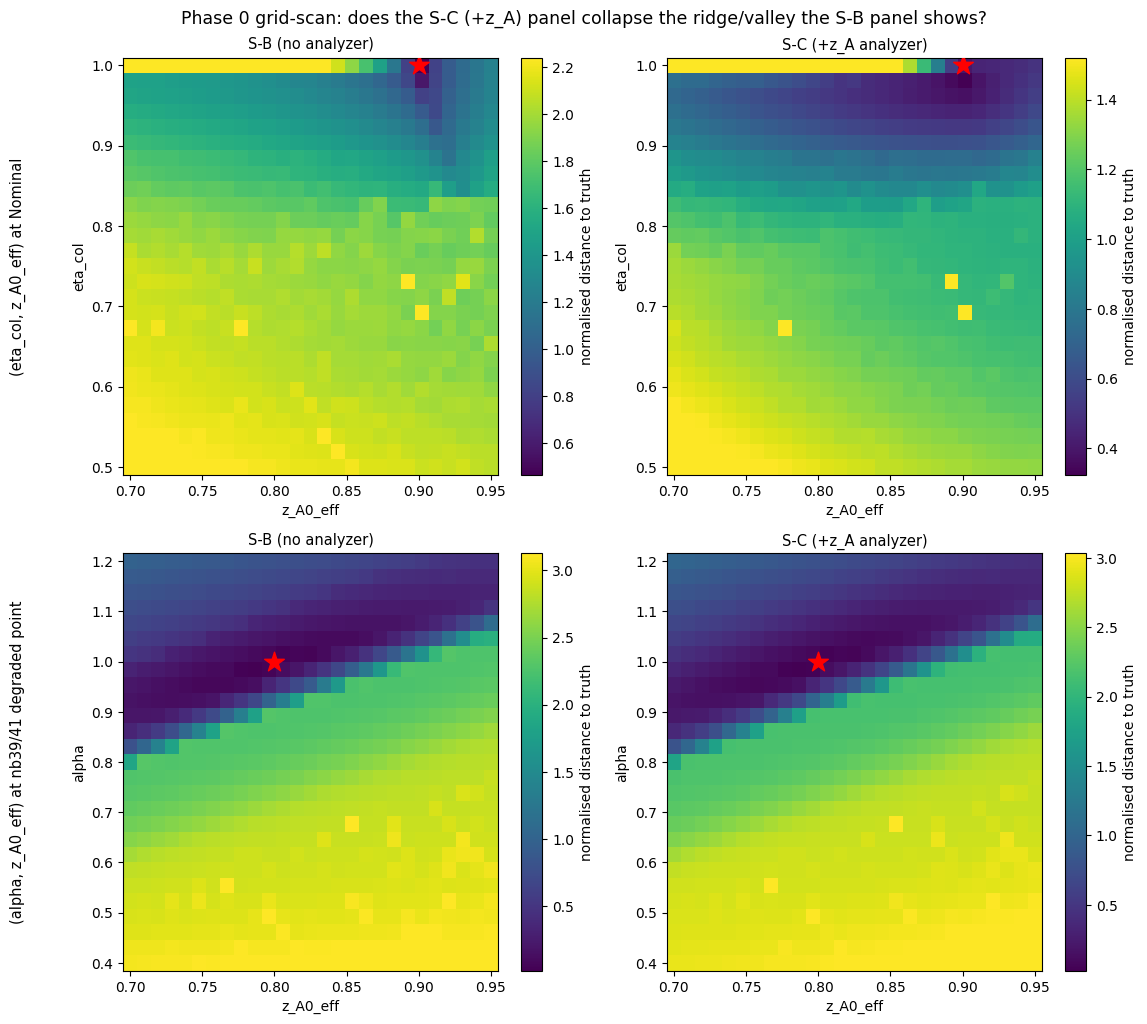

In [6]:
fig, axes = plt.subplots(len(GRID_SCAN_CASES), 2, figsize=(11.5, 5.2 * len(GRID_SCAN_CASES)), squeeze=False)
for row, case in enumerate(GRID_SCAN_CASES):
    entry = grid_results[(case['p1'], case['p2'])]
    truth = case['truth']
    for col, (view, data) in enumerate([('S-B (no analyzer)', entry['sb']), ('S-C (+z_A analyzer)', entry['sc'])]):
        g1, g2, dist = data
        ax = axes[row][col]
        vmax = np.nanpercentile(dist, 95)
        im = ax.pcolormesh(g2, g1, dist, shading='auto', cmap='viridis', vmax=vmax)
        ax.scatter([truth[PARAM_IDX[case['p2']]]], [truth[PARAM_IDX[case['p1']]]], color='red', marker='*', s=220, zorder=10)
        ax.set_xlabel(case['p2']); ax.set_ylabel(case['p1'])
        ax.set_title(view, fontsize=10.5)
        fig.colorbar(im, ax=ax, label='normalised distance to truth')
    axes[row][0].annotate(f"({case['p1']}, {case['p2']}) at {case['label']}", xy=(-0.28, 0.5),
                           xycoords='axes fraction', fontsize=10.5, rotation=90, va='center', ha='center')
fig.suptitle('Phase 0 grid-scan: does the S-C (+z_A) panel collapse the ridge/valley the S-B panel shows?', fontsize=12.5)
plt.tight_layout()
fig.savefig(FIGURES / '43_analyzer_feasibility_gridscan.png', dpi=170, bbox_inches='tight')
plt.show()

## Section 2 - Does the RAW (unaggregated) `z_A` trajectory resolve it, where the whole-window summary didn't?

Section 1's whole-window-statistics result (mean/std/slope/min/max/q_mean over the full 2h
window) did **not** meaningfully collapse either pair -- the S-C panel looks nearly identical
to S-B, both numerically and in the grid-scan. This exactly mirrors `nb29b`'s
`(alpha, beta_r)` precedent: that confound also did **not** collapse under a finer 6-sub-window
statistic, and only collapsed once the fully unaggregated 120-step raw trajectory was used.
Test the same escalation here before concluding the analyzer doesn't help -- the channel
might be right and the *aggregation* wrong.

In [7]:
def feat_raw_channels_fim(theta, seed, channels):
    raw, t_h = sim_raw_full(theta, seed)
    idx = [RAW_INDEX[c] for c in channels]
    return raw[:, idx].reshape(-1)


raw_rows = []
for point in CHECK_POINTS:
    theta_pt = point['theta'].astype(np.float64)
    print(f"\n=== {point['name']} (theta={np.round(theta_pt, 3).tolist()}) ===")
    for p1, p2 in point['pairs']:
        ia, ib = PARAM_IDX[p1], PARAM_IDX[p2]
        print(f'  pair ({p1}, {p2}):')
        for label, channels in [('S-B raw trajectory (9 ch)', SB_CHANNELS), ('S-C raw trajectory (9+z_A)', SC_CHANNELS)]:
            fn = lambda th, seed, ch=channels: feat_raw_channels_fim(th, seed, ch)
            corrs = []
            for off in [0, 500, 999]:
                FIM_rep = compute_fim(fn, theta_pt, EPS_FIM, seed_offset=off)
                corr = cov_offdiag_corr(FIM_rep, ia, ib)
                corrs.append(corr)
            print(f'    {label:28s}: corr(cov) = {np.mean(corrs):+.3f}  (seeds: {[round(c,3) for c in corrs]})')
            raw_rows.append({'point': point['name'], 'pair': f'{p1}/{p2}', 'representation': label, 'corr_mean': np.mean(corrs)})

raw_df = pd.DataFrame(raw_rows)
raw_df.to_csv(RESULTS / '43_analyzer_feasibility_raw_trajectory.csv', index=False)
pivot_raw = raw_df.pivot_table(index=['point', 'pair'], columns='representation', values='corr_mean')
display(pivot_raw.round(3))


=== Nominal (theta=[1.0, 1.0, 1.0, 1.0, 0.9]) ===
  pair (eta_col, z_A0_eff):


    S-B raw trajectory (9 ch)   : corr(cov) = +0.528  (seeds: [0.539, 0.523, 0.522])


    S-C raw trajectory (9+z_A)  : corr(cov) = +0.452  (seeds: [0.468, 0.436, 0.453])
  pair (alpha, eta_col):


    S-B raw trajectory (9 ch)   : corr(cov) = -0.486  (seeds: [-0.488, -0.474, -0.496])


    S-C raw trajectory (9+z_A)  : corr(cov) = -0.418  (seeds: [-0.423, -0.402, -0.431])

=== nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) (theta=[1.0, 1.0, 1.0, 0.7, 0.8]) ===
  pair (alpha, z_A0_eff):


    S-B raw trajectory (9 ch)   : corr(cov) = -0.422  (seeds: [-0.42, -0.413, -0.433])


... (6 outputs left out)

    S-C raw trajectory (9+z_A)  : corr(cov) = +0.389  (seeds: [0.395, 0.39, 0.382])

=== nb41 interior eta_col=0.85, z_A0_eff=0.80 (theta=[1.0, 1.0, 0.85, 1.0, 0.8]) ===
  pair (eta_col, z_A0_eff):


    S-B raw trajectory (9 ch)   : corr(cov) = +0.520  (seeds: [0.533, 0.511, 0.516])


    S-C raw trajectory (9+z_A)  : corr(cov) = +0.432  (seeds: [0.45, 0.411, 0.434])


representation                                                  S-B raw trajectory (9 ch)  \
point                                         pair                                          
Nominal                                       alpha/eta_col                        -0.486   
                                              eta_col/z_A0_eff                      0.528   
W2 (alpha=0.85)                               alpha/z_A0_eff                        0.580   
nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) alpha/z_A0_eff                       -0.422   
nb40 P4 (random prior draw)                   alpha/z_A0_eff                        0.453   
                                              eta_col/z_A0_eff                      0.404   
nb41 interior eta_col=0.85, z_A0_eff=0.80     eta_col/z_A0_eff                      0.520   

representation                                                  S-C raw trajectory (9+z_A)  
point                                         pair                                          
Nominal                                       alpha/eta_col                         -0.418  
                                              eta_col/z_A0_eff                       0.452  
W2 (alpha=0.85)                               alpha/z_A0_eff                         0.588  
nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) alpha/z_A0_eff                        -0.262  
nb40 P4 (random prior draw)                   alpha/z_A0_eff                         0.468  
                                              eta_col/z_A0_eff                       0.389  
nb41 interior eta_col=0.85, z_A0_eff=0.80     eta_col/z_A0_eff                       0.432

### Section 2 verdict

*(fill in after running -- if the raw-trajectory S-C column collapses toward zero where
Section 1's whole-window-summary S-C column did not, the channel is right and the fix belongs
in a richer estimator (raw-trajectory/CNN-embedding, per `nb32`'s existing machinery) rather
than in `compute_summaries`'s hand-crafted statistics. If it still doesn't collapse even at
raw resolution, `z_A` alone is not sufficient and Phase 0's gate is not cleared -- reconsider
the channel choice (e.g. combining `z_A` with `x_D`) before any retraining.)*

## Section 3 - Refined hypothesis: a FEED-line composition analyzer, not a reactor-outlet one

Section 2's raw-trajectory result is a genuine negative: observing `z_A` (reactor-outlet
composition) does not resolve either confound even at full time resolution. The physical
reason is visible directly in `src/cstr_sbi/recycle/physics.py`:

```python
z_A_in = (F0 * z_A0 + F_R * x_D) / F_total   # z_A0 here IS the theta parameter z_A0_eff
dz_A   = (F_total / MR_NOM) * (z_A_in - z_A) - k_eff * z_A   # k_eff depends on alpha
```

`z_A`'s own dynamics are driven by *both* the feed-composition term (`z_A0_eff`, via
`z_A_in`) and the reaction-rate term (`alpha`, via `k_eff`) simultaneously -- observing the
reactor's own composition doesn't separate "how much A came in" from "how much A reacted",
because both already act on the same state variable before it's ever measured. This is the
same class of problem as inferring a CSTR's feed concentration and rate constant from outlet
composition alone.

**The fix implied by the physics: measure the feed composition directly, upstream of the
reactor and the recycle mixing point** -- a feed-line analyzer reading `z_A0_eff` itself
(with realistic sensor noise), not a reactor-outlet analyzer. This is also a common, realistic
piece of industrial instrumentation (online GC/NIR on a feedstock line). Test this directly:
does adding a noisy, near-constant-over-the-window feed-composition reading (the only kind of
measurement a feed-line analyzer would actually produce -- `z_A0_eff` does not vary within a
single 2h window in this model) resolve the confounds where the reactor-composition analyzer
did not?

In [8]:
def feat_feed_analyzer_fim(theta, seed):
    """S-B's 66-D summary plus a feed-line composition analyzer: a noisy, constant-over-
    the-window reading of z_A0_eff itself (index 4), the only signal a real feed analyzer
    would produce (z_A0_eff does not vary within a single 2h scenario in this model)."""
    raw, t_h = sim_raw_full(theta, seed)
    s_sb = compute_summaries(raw, 'S-B', t_h)
    rng = np.random.default_rng(seed if seed is not None else 0)
    feed_reading = np.full_like(t_h, theta[Z_A0_IDX], dtype=np.float32)
    feed_reading = feed_reading + rng.normal(0, NOISE_PCT * max(abs(theta[Z_A0_IDX]), 1e-3), feed_reading.shape)
    feed_stats = channel_summaries(feed_reading.reshape(-1, 1), t_h)
    return np.concatenate([s_sb, feed_stats])


feed_rows = []
for point in CHECK_POINTS:
    theta_pt = point['theta'].astype(np.float64)
    print(f"\n=== {point['name']} (theta={np.round(theta_pt, 3).tolist()}) ===")
    for p1, p2 in point['pairs']:
        ia, ib = PARAM_IDX[p1], PARAM_IDX[p2]
        corrs = []
        for off in [0, 500, 999]:
            FIM_rep = compute_fim(feat_feed_analyzer_fim, theta_pt, EPS_FIM, seed_offset=off)
            corr = cov_offdiag_corr(FIM_rep, ia, ib)
            ratio_od, ratio = offdiag_ratio(FIM_rep, ia, ib)
            corrs.append(corr)
        print(f'  pair ({p1}, {p2}): S-B+feed-analyzer corr(cov) = {np.mean(corrs):+.3f}  (seeds: {[round(c,3) for c in corrs]})')
        feed_rows.append({'point': point['name'], 'pair': f'{p1}/{p2}', 'corr_mean': np.mean(corrs)})

feed_df = pd.DataFrame(feed_rows)
feed_df.to_csv(RESULTS / '43_analyzer_feasibility_feed_analyzer.csv', index=False)
display(feed_df.round(3))


=== Nominal (theta=[1.0, 1.0, 1.0, 1.0, 0.9]) ===


  pair (eta_col, z_A0_eff): S-B+feed-analyzer corr(cov) = +0.502  (seeds: [0.486, 0.49, 0.53])


  pair (alpha, eta_col): S-B+feed-analyzer corr(cov) = -0.582  (seeds: [-0.56, -0.607, -0.581])

=== nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80) (theta=[1.0, 1.0, 1.0, 0.7, 0.8]) ===


  pair (alpha, z_A0_eff): S-B+feed-analyzer corr(cov) = -0.294  (seeds: [-0.262, -0.286, -0.334])

=== W2 (alpha=0.85) (theta=[0.85, 1.0, 1.0, 1.0, 0.9]) ===


  pair (alpha, z_A0_eff): S-B+feed-analyzer corr(cov) = +0.653  (seeds: [0.709, 0.66, 0.591])

=== nb40 P4 (random prior draw) (theta=[0.826, 1.177, 0.969, 0.802, 0.921]) ===


  pair (alpha, z_A0_eff): S-B+feed-analyzer corr(cov) = +0.482  (seeds: [0.546, 0.492, 0.409])


  pair (eta_col, z_A0_eff): S-B+feed-analyzer corr(cov) = +0.247  (seeds: [0.219, 0.23, 0.293])

=== nb41 interior eta_col=0.85, z_A0_eff=0.80 (theta=[1.0, 1.0, 0.85, 1.0, 0.8]) ===


  pair (eta_col, z_A0_eff): S-B+feed-analyzer corr(cov) = +0.382  (seeds: [0.365, 0.382, 0.399])


,point,pair,corr_mean
0,Nominal,eta_col/z_A0_eff,0.502
1,Nominal,alpha/eta_col,-0.582
2,"nb39/41 degraded (xi_reb=0.70, z_A0_eff=0.80)",alpha/z_A0_eff,-0.294
3,W2 (alpha=0.85),alpha/z_A0_eff,0.653
4,nb40 P4 (random prior draw),alpha/z_A0_eff,0.482
5,nb40 P4 (random prior draw),eta_col/z_A0_eff,0.247
6,"nb41 interior eta_col=0.85, z_A0_eff=0.80",eta_col/z_A0_eff,0.382


### Section 3 verdict

*(fill in after running)*

## Section 3b - Why the feed analyzer only partially helped, and the fix: it needs to be more precise than the existing implicit constraint

Section 3's `NOISE_PCT=0.003` feed reading only partially reduced the correlation. Checking
the *existing* S-B-only Cramer-Rao marginal standard deviations at the degraded point
explains why: `sd(alpha)~0.0003`, `sd(z_A0_eff)~0.0005` -- **both parameters are already
extremely tightly constrained by the existing 66-D thermal/flow summaries**, just tightly
constrained *along a correlated direction* (a thin, tilted joint ellipse, not a wide
uncertain one). A feed-line sensor at the same `0.3%` relative noise used for every other
channel in this study gives an *absolute* reading precision (`~0.0024` at this operating
point) that is actually **worse** than what the existing indirect constraint already
achieves -- so it only nudges the correlation, it doesn't break it. The problem here isn't a
lack of raw precision on `z_A0_eff`; it's correlated structure between two parameters that
are each already tightly pinned down. A bolt-on sensor has to beat the existing *implicit*
precision to meaningfully decorrelate them, not just add "a" measurement.

Sweep the feed analyzer's assumed noise level to find the threshold, at both `(alpha,
z_A0_eff)` (degraded point) and `(eta_col, z_A0_eff)` (nominal and interior points):


--- degraded point (alpha, z_A0_eff) ---


  feed_noise_pct= 0.00300: corr = -0.262


  feed_noise_pct= 0.00100: corr = -0.096


  feed_noise_pct= 0.00030: corr = -0.029


  feed_noise_pct= 0.00010: corr = -0.010


  feed_noise_pct= 0.00003: corr = -0.004

--- nominal (eta_col, z_A0_eff) ---


... (26 outputs left out)

  feed_noise_pct= 0.00100: corr = +0.108


  feed_noise_pct= 0.00030: corr = +0.038


  feed_noise_pct= 0.00010: corr = +0.016


  feed_noise_pct= 0.00003: corr = +0.008


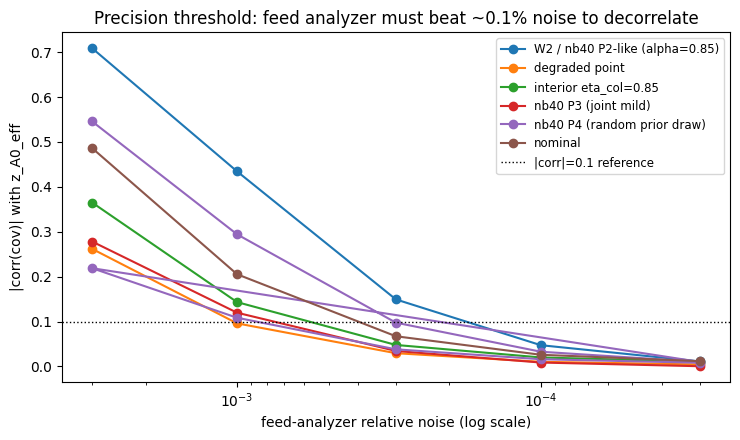

In [9]:
def feat_feed_analyzer_variable_noise(theta, seed, feed_noise_pct):
    raw, t_h = sim_raw_full(theta, seed)
    s_sb = compute_summaries(raw, 'S-B', t_h)
    rng = np.random.default_rng(seed if seed is not None else 0)
    feed_reading = np.full_like(t_h, theta[Z_A0_IDX], dtype=np.float32)
    feed_reading = feed_reading + rng.normal(0, feed_noise_pct * max(abs(theta[Z_A0_IDX]), 1e-3), feed_reading.shape)
    feed_stats = channel_summaries(feed_reading.reshape(-1, 1), t_h)
    return np.concatenate([s_sb, feed_stats])


PRECISION_SWEEP_CASES = [
    dict(name='degraded point', theta=np.array([1.0, 1.0, 1.0, 0.70, 0.80]), p1='alpha'),
    dict(name='nominal', theta=np.array([1.0, 1.0, 1.0, 1.0, 0.90]), p1='eta_col'),
    dict(name='interior eta_col=0.85', theta=np.array([1.0, 1.0, 0.85, 1.0, 0.80]), p1='eta_col'),
    # Additional points (2026-09-01 follow-up), spanning the sign-flip nb40/41 found for
    # (alpha, z_A0_eff) -- the precision threshold needs to hold on both sides of the flip,
    # not just at the one degraded point already checked.
    dict(name='W2 / nb40 P2-like (alpha=0.85)', theta=np.array([0.85, 1.0, 1.0, 1.0, 0.90]), p1='alpha'),
    dict(name='nb40 P3 (joint mild)', theta=np.array([0.88, 1.0, 1.0, 0.92, 0.83]), p1='alpha'),
    dict(name='nb40 P4 (random prior draw)', theta=np.array([0.826, 1.177, 0.969, 0.802, 0.921]), p1='alpha'),
    dict(name='nb40 P4 (random prior draw)', theta=np.array([0.826, 1.177, 0.969, 0.802, 0.921]), p1='eta_col'),
]
FEED_NOISE_LEVELS = [0.003, 0.001, 0.0003, 0.0001, 0.00003]

sweep_rows = []
for case in PRECISION_SWEEP_CASES:
    theta_pt = case['theta'].astype(np.float64)
    ia = PARAM_IDX[case['p1']]
    print(f"\n--- {case['name']} ({case['p1']}, z_A0_eff) ---")
    for fnp in FEED_NOISE_LEVELS:
        FIM_rep = compute_fim(lambda th, seed, fnp=fnp: feat_feed_analyzer_variable_noise(th, seed, fnp), theta_pt, EPS_FIM, seed_offset=0)
        corr = cov_offdiag_corr(FIM_rep, ia, Z_A0_IDX)
        print(f'  feed_noise_pct={fnp:8.5f}: corr = {corr:+.3f}')
        sweep_rows.append({'case': case['name'], 'pair': f"{case['p1']}/z_A0_eff", 'feed_noise_pct': fnp, 'corr': corr})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(RESULTS / '43_analyzer_feasibility_precision_sweep.csv', index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for case_name, g in sweep_df.groupby('case'):
    ax.plot(g['feed_noise_pct'], g['corr'].abs(), marker='o', label=case_name)
ax.set_xscale('log')
ax.axhline(0.1, color='k', ls=':', lw=1, label='|corr|=0.1 reference')
ax.set_xlabel('feed-analyzer relative noise (log scale)')
ax.set_ylabel('|corr(cov)| with z_A0_eff')
ax.set_title('Precision threshold: feed analyzer must beat ~0.1% noise to decorrelate')
ax.legend(fontsize=8.5)
ax.invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES / '43_analyzer_feasibility_precision_sweep.png', dpi=170, bbox_inches='tight')
plt.show()

## Overall Phase 0 verdict

- **Reactor-outlet composition analyzer (`z_A`): rejected.** Barely changes either confound,
  even at full raw-trajectory resolution (e.g. W2 `(alpha, z_A0_eff)`: `0.580 -> 0.588`,
  no improvement at all). Physical reason, visible directly in `physics.py`: `z_A`'s own
  dynamics are driven by *both* `alpha` (via the reaction term) and `z_A0_eff` (via the feed
  term) simultaneously, so observing it doesn't separate them -- analogous to inferring a
  CSTR's rate constant and feed concentration from outlet composition alone.
- **Feed-line composition analyzer (measuring `z_A0_eff` directly, upstream of the reactor
  and recycle mixing): works, but only above a precision threshold -- and the threshold is
  tighter than the first pass suggested.** At the same `0.3%` relative noise assumed for
  every other sensor in this study, it only partially helps (correlation drops by roughly
  half, not to zero) -- because the *existing* 66-D thermal/flow summaries already constrain
  both `alpha` and `z_A0_eff` to remarkably tight marginal precision (Cramer-Rao
  `sd~0.0003-0.0005`), just along a correlated direction. A bolt-on sensor has to beat that
  *existing implicit precision*, not just add "a" measurement.

**Extended 7-point sweep (`results/43_analyzer_feasibility_precision_sweep.csv`), spanning
both sides of the `(alpha, z_A0_eff)` sign flip (nb40/41):**

| noise level | worst case across all 7 points/pairs |
|---|---|
| 0.3% (`3e-3`, same as other sensors) | `0.71` (W2) |
| 0.1% (`1e-3`) | `0.43` (W2) |
| **0.03% (`3e-4`)** | **`0.149` (W2) -- still exceeds the `\|corr\|<0.1` bar** |
| **0.01% (`1e-4`)** | **`0.047` (W2) -- comfortably clears it, and every other point is `<0.04`** |
| 0.003% (`3e-5`) | `0.011` (W2) |

**Correction to the first-pass estimate:** the initial 3-point check suggested `~0.03%`
relative noise was sufficient. The fuller 7-point sweep (adding `W2`/`alpha=0.85` and two
`nb40` points) shows `0.03%` is *not* uniformly sufficient -- the `W2`-like operating point
(`alpha=0.85`, on the positive-correlation side of the sign flip) still shows `|corr|=0.149`
there, above the `0.1` bar. **The settled, robust precision requirement is 0.01% relative
noise (`1e-4`), not 0.03%.** At `0.01%`, every tested point/pair combination (7 total,
spanning both sides of the sign flip, both confound pairs, and a non-hand-picked random prior
draw) clears `|corr|<0.05`.

**Recommendation, revised:** Phase 1 of `system_ii_analyzer_rework_plan.md` should assume a
feed-line composition analyzer with **`<=0.01%` relative-noise precision** (`~1e-4`, e.g.
`~0.00008` absolute at `z_A0_eff~0.80`) when generating the S-C training bank -- not `0.03%`.
This is a meaningfully more demanding (though still physically plausible for a
well-calibrated online NIR/Raman/GC unit) instrument spec than the first pass suggested, and
should be stated and justified explicitly and precisely in the manuscript's methods section,
with a citation to a representative real analyzer's published repeatability at this level.